# TP 8 - Deep Learning: Predicción de Satisfacción de Pasajeros de Aerolínea

**Módulo 7 - Deep Learning (Opción 1: DNN).** Se retoma el dataset y los seis modelos del
TP de Machine Learning 2 (Módulo 6) y se los compara con Redes Neuronales Profundas.

**Integrantes:** Esteban Germán Rojas, Alexia Antonoglou, Ana Paula Athor,
Facundo Rojas, Agustín Alejandro Martínez

**Curso:** Diplomatura en Ciencia de Datos y Análisis Avanzado

Este notebook contiene el desarrollo completo que respalda el informe: todos los
resultados, tablas y figuras del informe salen de **una única ejecución completa**
(Reiniciar kernel → Ejecutar todo). Las secciones 1 a 10 reproducen el TP anterior;
las secciones 11 a 16 son el desarrollo de Deep Learning.

**Cómo ejecutarlo.** Funciona en VS Code (o Jupyter local) y en Google Colab: los CSV
`train (2).csv` y `test (2).csv` se buscan en la carpeta del notebook y, si no están,
en `/content/` (Colab).

**Medición de tiempos.** Todos los modelos se entrenan y predicen con **un solo hilo de
CPU**: `n_jobs=1` en scikit-learn y TensorFlow limitado a 1 hilo y sin GPU. Así la
comparación de costo computacional es justa. Las búsquedas de hiperparámetros y las
repeticiones con otras semillas sí usan todos los núcleos, porque no forman parte del
tiempo reportado. Los tiempos absolutos dependen del equipo; lo comparable son las
proporciones entre modelos.

**Optimización de hiperparámetros (TP6).** Se optimizan con `GridSearchCV` el Árbol, el
SVM y el Gradient Boosting. La Regresión Logística, el KNN y el Random Forest quedan en
su configuración estándar; esa asimetría juega en contra de ellos y está declarada como
limitación.

## 1. Problema y objetivo

Problema de **clasificacion binaria**: predecir si un pasajero de aerolinea queda
**insatisfecho** (`neutral or dissatisfied`) o **satisfecho** (`satisfied`) con el
servicio, a partir de datos demograficos, caracteristicas del vuelo y calificaciones
de distintos aspectos del servicio.

**Definicion de la clase positiva:** se codifica `1 = insatisfecho`. Esta decision no
es cosmetica: define que es un falso negativo. El objetivo de negocio es **detectar
pasajeros insatisfechos para poder intervenir**, por lo que el error costoso es dejar
pasar a un insatisfecho sin detectarlo. Con esta codificacion, ese error es un falso
negativo y queda capturado por el **recall**.

## 2. Importacion de librerias

In [ ]:
# Manipulacion de datos
import pandas as pd
import numpy as np
import time  # para medir el costo computacional de cada modelo
import os, platform
from pathlib import Path

# Visualizacion
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocesamiento y validacion
from sklearn.model_selection import (train_test_split, cross_val_score,
                                     GridSearchCV, StratifiedKFold)
from sklearn.preprocessing import StandardScaler

# Modelos
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Metricas
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

sns.set_style('whitegrid')
# Arial en los graficos (misma fuente que el informe); si no esta instalada,
# matplotlib usa DejaVu Sans sin cortar la ejecucion.
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
import logging; logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
FIG_DIR = Path('figuras'); FIG_DIR.mkdir(exist_ok=True)
pd.set_option('display.max_columns', None)
RANDOM_STATE = 42  # semilla fija: resultados reproducibles

## 3. Carga del dataset

In [ ]:
# El dataset viene ya dividido en dos archivos por el proveedor.
# Se buscan en la carpeta del notebook (VS Code / Jupyter) y, si no estan, en /content (Colab).
CANDIDATAS = [Path('.'), Path('/content')]
DATA_DIR = next((p for p in CANDIDATAS if (p / 'train (2).csv').exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("No se encontraron 'train (2).csv' y 'test (2).csv' "
                            "ni en la carpeta del notebook ni en /content.")

train_df = pd.read_csv(DATA_DIR / 'train (2).csv')
test_df  = pd.read_csv(DATA_DIR / 'test (2).csv')

print("Carpeta de datos:", DATA_DIR.resolve())
print("Dimensiones train:", train_df.shape)
print("Dimensiones test :", test_df.shape)
train_df.head(3)

Carpeta de datos: /home/claude/tp8
Dimensiones train: (103904, 25)
Dimensiones test : (25976, 25)


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,5,3,5,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,1,3,1,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,5,5,5,5,4,3,4,4,4,5,0,0.0,satisfied


## 4. Analisis exploratorio (EDA)

Revisamos estructura, tipos, valores faltantes y balance de la variable objetivo.

In [ ]:
print("Columnas:", list(train_df.columns), "\n")
print("Valores nulos por columna (solo las que tienen):")
print(train_df.isnull().sum()[train_df.isnull().sum() > 0], "\n")
print("Nulos en test:")
print(test_df.isnull().sum()[test_df.isnull().sum() > 0])

Columnas: ['Unnamed: 0', 'id', 'Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Inflight service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'satisfaction'] 

Valores nulos por columna (solo las que tienen):
Arrival Delay in Minutes    310
dtype: int64 

Nulos en test:
Arrival Delay in Minutes    83
dtype: int64


Distribucion de la variable objetivo (%):
satisfaction
neutral or dissatisfied    56.7
satisfied                  43.3
Name: proportion, dtype: float64


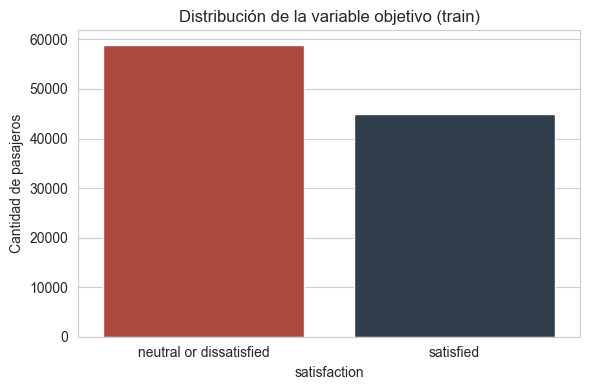

In [ ]:
# Balance de la variable objetivo: condiciona que metrica conviene usar.
dist = train_df['satisfaction'].value_counts(normalize=True) * 100
print("Distribucion de la variable objetivo (%):")
print(dist.round(1))

plt.figure(figsize=(6, 4))
vc = train_df['satisfaction'].value_counts()
sns.barplot(x=vc.index, y=vc.values, hue=vc.index,
            palette=['#c0392b', '#2c3e50'], legend=False)
plt.title('Distribución de la variable objetivo (train)')
plt.xlabel('satisfaction'); plt.ylabel('Cantidad de pasajeros')
plt.tight_layout(); plt.savefig(FIG_DIR / 'fig_distribucion_objetivo.png', dpi=200); plt.show()

## 5. Feature engineering

Pasos aplicados, identicos en train y en test:

1. **Eliminar `Unnamed: 0` e `id`**: son identificadores, no aportan senal predictiva.
2. **Eliminar filas con nulos** en `Arrival Delay in Minutes` (~0,3% del total).
3. **Codificar la variable objetivo**: `1 = neutral or dissatisfied` (insatisfecho,
   clase positiva), `0 = satisfied`.
4. **One-Hot Encoding** de todas las categoricas con `pd.get_dummies(drop_first=True)`.
   Se usa el mismo mecanismo para las binarias y para `Class` (3 categorias), para no
   imponer un orden que no existe. Al usar `get_dummies` no se ajusta ningun
   codificador sobre el set de test.
5. **Estandarizacion** con `StandardScaler`, ajustado **solo con train**. Es necesaria
   para Regresion Logistica, KNN y SVM, que son sensibles a la escala. Los modelos de
   arboles usan los datos sin estandarizar (no lo necesitan).

In [ ]:
CATEGORICAS = ['Gender', 'Customer Type', 'Type of Travel', 'Class']

def preparar_datos(df):
    df = df.copy()
    df = df.drop(columns=['Unnamed: 0', 'id'], errors='ignore')   # 1
    df = df.dropna()   # 2 - los unicos nulos estan en Arrival Delay in Minutes
    df['satisfaction'] = df['satisfaction'].map(                  # 3
        {'neutral or dissatisfied': 1, 'satisfied': 0})
    df = pd.get_dummies(df, columns=CATEGORICAS, drop_first=True) # 4
    return df

train_prep = preparar_datos(train_df)
test_prep  = preparar_datos(test_df)

X_train = train_prep.drop(columns=['satisfaction'])
y_train = train_prep['satisfaction']
X_test  = test_prep.drop(columns=['satisfaction']).reindex(
    columns=X_train.columns, fill_value=0)   # alineamos columnas por las dudas
y_test  = test_prep['satisfaction']

print("Predictoras finales (", X_train.shape[1], "):", list(X_train.columns))
print("\nX_train:", X_train.shape, "| X_test:", X_test.shape)
print("Proporcion de insatisfechos -> train:", round(y_train.mean(), 4),
      "| test:", round(y_test.mean(), 4))

Predictoras finales ( 23 ): ['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Inflight service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender_Male', 'Customer Type_disloyal Customer', 'Type of Travel_Personal Travel', 'Class_Eco', 'Class_Eco Plus']

X_train: (103594, 23) | X_test: (25893, 23)
Proporcion de insatisfechos -> train: 0.5666 | test: 0.5611


In [ ]:
# 5. Estandarizacion: el scaler se ajusta SOLO con train para no filtrar
# informacion del test al entrenamiento.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)
print("Datos estandarizados. Shape:", X_train_scaled.shape)

Datos estandarizados. Shape: (103594, 23)


## 6. Metrica de evaluacion

La variable objetivo esta **razonablemente balanceada** (56,7% / 43,3%), asi que la
**Accuracy** no es enganosa y se reporta como referencia.

Sin embargo, la metrica **principal es el F1-score sobre la clase "insatisfecho"**,
por dos razones:

1. **El costo del error no es simetrico.** Dejar pasar a un pasajero insatisfecho
   (falso negativo) implica perder la oportunidad de retenerlo; marcar de mas a uno
   satisfecho (falso positivo) solo cuesta una accion comercial innecesaria. Por eso
   se reporta tambien el **recall**, que mide directamente que proporcion de
   insatisfechos logramos detectar.
2. **El F1 no premia a un modelo que se incline por la clase mayoritaria**, cosa que
   la accuracy si puede tolerar.

Se usa F1 y no una metrica puramente de recall porque un modelo que marque a todos
como insatisfechos tendria recall perfecto y seria inutil: el F1 penaliza esa
degradacion de la precision. El recall se usa como criterio de desempate cuando dos
modelos tienen F1 equivalente.

## 7. Entrenamiento y evaluacion

La funcion siguiente entrena, mide **tiempo de entrenamiento y de prediccion** y
evalua sobre el set de test completo.

Medir tambien el tiempo de prediccion es importante: hay modelos que entrenan casi
instantaneamente pero son caros al predecir (KNN), y en produccion la prediccion es
la operacion que se repite.

In [ ]:
resultados, predicciones, modelos_entrenados = [], {}, {}

# Calcula las metricas de un modelo ya entrenado y las guarda en la tabla comun.
def registrar(nombre, modelo, y_pred, t_fit, t_pred, yte=None, nota=''):
    yte = y_test if yte is None else yte
    fila = {'Modelo': nombre,
            'Accuracy':  accuracy_score(yte, y_pred),
            'Precision': precision_score(yte, y_pred),
            'Recall':    recall_score(yte, y_pred),
            'F1-score':  f1_score(yte, y_pred),
            'Tiempo_entren_seg': t_fit,
            'Tiempo_predic_seg': t_pred,
            'Nota': nota}
    # Si el modelo ya estaba registrado (celda re-ejecutada), se reemplaza su fila
    # en lugar de duplicarla.
    resultados[:] = [r for r in resultados if r['Modelo'] != nombre]
    resultados.append(fila)
    predicciones[nombre] = y_pred
    modelos_entrenados[nombre] = modelo
    print(f"--- {nombre} ---")
    print(f"Accuracy {fila['Accuracy']:.4f} | Precision {fila['Precision']:.4f} | "
          f"Recall {fila['Recall']:.4f} | F1 {fila['F1-score']:.4f}")
    print(f"Tiempo entrenamiento {t_fit:.2f}s | Tiempo prediccion {t_pred:.2f}s\n")
    return modelo

def entrenar_y_evaluar(nombre, modelo, Xtr, Xte, ytr=None, yte=None, nota=''):
    ytr = y_train if ytr is None else ytr
    t0 = time.perf_counter(); modelo.fit(Xtr, ytr)
    t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); y_pred = modelo.predict(Xte)
    t_pred = time.perf_counter() - t0
    return registrar(nombre, modelo, y_pred, t_fit, t_pred, yte=yte, nota=nota)

### 7.1 Modelo 1 - Regresion Logistica *(obligatorio: visto en Machine Learning 1)*

Sin optimizar: configuracion estandar.

In [ ]:
# Modelo lineal. Sirve como linea de base: si un modelo complejo no le gana
# claramente, no se justifica su costo. Usa datos estandarizados.
entrenar_y_evaluar(
    'Regresion Logistica',
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    X_train_scaled, X_test_scaled)

--- Regresion Logistica ---
Accuracy 0.8718 | Precision 0.8736 | Recall 0.9021 | F1 0.8876
Tiempo entrenamiento 0.28s | Tiempo prediccion 0.00s



,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

### 7.2 Modelo 2 - KNN *(visto en Machine Learning 1)*

Sin optimizar: k=5, el valor por defecto.

In [ ]:
# Modelo "perezoso": no aprende parametros, guarda el set de entrenamiento.
# Por eso el entrenamiento es instantaneo y el costo se paga al predecir.
entrenar_y_evaluar(
    'KNN',
    KNeighborsClassifier(n_neighbors=5, n_jobs=1),
    X_train_scaled, X_test_scaled)

--- KNN ---
Accuracy 0.9277 | Precision 0.9136 | Recall 0.9621 | F1 0.9372
Tiempo entrenamiento 0.02s | Tiempo prediccion 4.53s



,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",1


### 7.3 Modelo 3 - Arbol de Decision *(optimizado con GridSearchCV)*

In [ ]:
# Los arboles no necesitan estandarizacion: usamos los datos crudos.
param_arbol = {'criterion': ['gini', 'entropy'], 'max_depth': [None, 10, 20, 30]}
grid_arbol = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                          param_arbol, cv=3, scoring='f1', n_jobs=-1)
grid_arbol.fit(X_train, y_train)
print("Mejores hiperparametros del Arbol:", grid_arbol.best_params_, "\n")

entrenar_y_evaluar(
    'Arbol de Decision',
    DecisionTreeClassifier(random_state=RANDOM_STATE, **grid_arbol.best_params_),
    X_train, X_test)

Mejores hiperparametros del Arbol: {'criterion': 'entropy', 'max_depth': 20} 



--- Arbol de Decision ---
Accuracy 0.9517 | Precision 0.9520 | Recall 0.9625 | F1 0.9572
Tiempo entrenamiento 0.47s | Tiempo prediccion 0.01s



,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curren

### 7.4 Modelo 4 - SVM con kernel RBF

El SVM con kernel RBF tiene un costo de entrenamiento que crece de forma
**superlineal** con la cantidad de filas. En lugar de asumirlo, lo **medimos**:
entrenamos el mismo SVM con muestras estratificadas crecientes y observamos como
evolucionan el tiempo y el F1. El exponente empirico que sale de esa curva es
**n^2,2**; extrapolado, el train completo costaria del orden de tres minutos. Aun
asi el modelo final se queda con la muestra de 40.000 (38,6% del train), y eso
queda declarado como limite del trabajo: la extrapolacion del costo es confiable,
la del F1 no lo es porque la metrica satura.

In [ ]:
# Busqueda de hiperparametros sobre una muestra chica (el grid es caro).
X_g, _, y_g, _ = train_test_split(X_train_scaled, y_train, train_size=10000,
                                  stratify=y_train, random_state=RANDOM_STATE)
grid_svm = GridSearchCV(SVC(kernel='rbf', random_state=RANDOM_STATE),
                        {'C': [1, 10], 'gamma': ['scale', 0.1]},
                        cv=3, scoring='f1', n_jobs=-1)
grid_svm.fit(X_g, y_g)
print("Mejores hiperparametros del SVM:", grid_svm.best_params_)

Mejores hiperparametros del SVM: {'C': 10, 'gamma': 'scale'}


In [ ]:
# Curva de costo: como escala el SVM al crecer la muestra de entrenamiento.
# El ajuste con n=40.000 es ademas el modelo final, asi que se reutiliza
# (no se vuelve a entrenar).
curva_svm = []
N_FINAL_SVM = 40000

for n in [5000, 15000, N_FINAL_SVM]:
    X_s, _, y_s, _ = train_test_split(X_train_scaled, y_train, train_size=n,
                                      stratify=y_train, random_state=RANDOM_STATE)
    svm_n = SVC(kernel='rbf', random_state=RANDOM_STATE, **grid_svm.best_params_)
    t0 = time.perf_counter(); svm_n.fit(X_s, y_s); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); y_pred_n = svm_n.predict(X_test_scaled)
    t_pred = time.perf_counter() - t0
    f1_n = f1_score(y_test, y_pred_n)
    curva_svm.append({'n': n, 'tiempo_seg': t_fit, 'f1_test': f1_n,
                      'vectores_soporte': int(svm_n.n_support_.sum())})
    print(f"n={n:6d} | fit {t_fit:7.2f}s | F1 test {f1_n:.4f} | "
          f"vectores de soporte {svm_n.n_support_.sum()}")
    if n == N_FINAL_SVM:      # este es el modelo final: registramos sus metricas
        registrar('SVM (RBF)', svm_n, y_pred_n, t_fit, t_pred,
                  nota=f'entrenado con muestra estratificada de {N_FINAL_SVM} filas '
                       f'({N_FINAL_SVM/len(y_train):.1%} del train)')

df_curva = pd.DataFrame(curva_svm)
print(df_curva.round(4).to_string(index=False))

n=  5000 | fit    0.27s | F1 test 0.9407 | vectores de soporte 1176


n= 15000 | fit    2.36s | F1 test 0.9522 | vectores de soporte 2906


n= 40000 | fit   23.05s | F1 test 0.9603 | vectores de soporte 6229
--- SVM (RBF) ---
Accuracy 0.9550 | Precision 0.9517 | Recall 0.9690 | F1 0.9603
Tiempo entrenamiento 23.05s | Tiempo prediccion 8.19s

    n  tiempo_seg  f1_test  vectores_soporte
 5000      0.2662   0.9407              1176
15000      2.3639   0.9522              2906
40000     23.0452   0.9603              6229


### 7.5 Modelo 5 - Random Forest *(ensamble en paralelo, bagging)*

Sin optimizar: 300 arboles con los parametros por defecto del resto.

In [ ]:
# 300 arboles con submuestreo de variables. n_jobs=1 para que el tiempo sea
# comparable con el del resto de los modelos.
entrenar_y_evaluar(
    'Random Forest',
    RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1),
    X_train, X_test)

--- Random Forest ---
Accuracy 0.9632 | Precision 0.9565 | Recall 0.9789 | F1 0.9676
Tiempo entrenamiento 26.98s | Tiempo prediccion 1.07s



,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

### 7.6 Modelo 6 - Gradient Boosting *(ensamble secuencial, optimizado)*

Se optimizan sus hiperparametros con GridSearchCV, igual que el Arbol y el SVM.
Compararlo con valores por defecto contra modelos ajustados seria una comparacion
sesgada.

In [ ]:
# El grid se hace sobre una muestra por costo; el modelo final se entrena
# con el train completo.
X_gb, _, y_gb, _ = train_test_split(X_train, y_train, train_size=8000,
                                    stratify=y_train, random_state=RANDOM_STATE)
grid_gb = GridSearchCV(GradientBoostingClassifier(random_state=RANDOM_STATE),
                       {'n_estimators': [100, 200], 'max_depth': [3, 5]},
                       cv=3, scoring='f1', n_jobs=-1)
grid_gb.fit(X_gb, y_gb)
print("Mejores hiperparametros del Gradient Boosting:", grid_gb.best_params_, "\n")

entrenar_y_evaluar(
    'Gradient Boosting',
    GradientBoostingClassifier(random_state=RANDOM_STATE, **grid_gb.best_params_),
    X_train, X_test)

Mejores hiperparametros del Gradient Boosting: {'max_depth': 5, 'n_estimators': 200} 



--- Gradient Boosting ---
Accuracy 0.9625 | Precision 0.9559 | Recall 0.9782 | F1 0.9669
Tiempo entrenamiento 48.87s | Tiempo prediccion 0.14s



,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",200
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are'friedman_mse' for the mean squared error with improvement score byFriedman, 'squared_error' for mean squared error. The default value of'friedman_mse' is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",5
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, 

## 8. Validacion cruzada (5-fold)

La validacion cruzada se corre sobre una **unica muestra comun de 10.000 registros**
para los seis modelos: el SVM no puede correr sobre el train completo, y comparar su
CV contra la de modelos validados con 103.594 filas seria mezclar cosas distintas.

**Como leerla.** Cada fold entrena con 8.000 filas, trece veces menos que el modelo
final. Eso tiene dos consecuencias: sus valores absolutos no son comparables contra
la columna de test, y **el orden que da tampoco transfiere de forma automatica** al
regimen de entrenamiento real. La curva del SVM de la seccion anterior lo muestra:
solo cambiar el tamano de muestra le mueve el F1 en 0,0196, mas que cualquier
diferencia entre los dos primeros modelos. Por eso la CV se usa para **verificar
estabilidad** y como evidencia secundaria, no como criterio de desempate.

In [ ]:
idx_cv, _ = train_test_split(np.arange(len(y_train)), train_size=10000,
                             stratify=y_train, random_state=RANDOM_STATE)
X_cv_raw = X_train.iloc[idx_cv]
X_cv_sc  = X_train_scaled[idx_cv]
y_cv     = y_train.iloc[idx_cv]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

modelos_cv = {
 'Regresion Logistica': (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), X_cv_sc),
 'KNN':                 (KNeighborsClassifier(n_neighbors=5), X_cv_sc),
 'Arbol de Decision':   (DecisionTreeClassifier(random_state=RANDOM_STATE,
                         **grid_arbol.best_params_), X_cv_raw),
 'SVM (RBF)':           (SVC(kernel='rbf', random_state=RANDOM_STATE,
                         **grid_svm.best_params_), X_cv_sc),
 'Random Forest':       (RandomForestClassifier(n_estimators=300,
                         random_state=RANDOM_STATE), X_cv_raw),
 'Gradient Boosting':   (GradientBoostingClassifier(random_state=RANDOM_STATE,
                         **grid_gb.best_params_), X_cv_raw),
}

cv_scores = {}
for nombre, (modelo, X_) in modelos_cv.items():
    s = cross_val_score(modelo, X_, y_cv, cv=cv, scoring='f1', n_jobs=-1)
    cv_scores[nombre] = (s.mean(), s.std())
    print(f"{nombre:22s} -> F1 CV = {s.mean():.4f} (+/- {s.std():.4f})")

Regresion Logistica    -> F1 CV = 0.8901 (+/- 0.0048)


KNN                    -> F1 CV = 0.9211 (+/- 0.0013)


Arbol de Decision      -> F1 CV = 0.9364 (+/- 0.0036)


SVM (RBF)              -> F1 CV = 0.9431 (+/- 0.0030)


Random Forest          -> F1 CV = 0.9514 (+/- 0.0049)


Gradient Boosting      -> F1 CV = 0.9606 (+/- 0.0033)


## 9. Tabla comparativa de resultados

In [ ]:
df_resultados = pd.DataFrame(resultados).set_index('Modelo')
df_resultados['F1_CV_medio'] = [cv_scores[m][0] for m in df_resultados.index]
df_resultados['F1_CV_desvio'] = [cv_scores[m][1] for m in df_resultados.index]
df_resultados = df_resultados.sort_values('F1-score', ascending=False)
df_resultados.to_csv('resultados_modelos.csv')

df_resultados.drop(columns=['Nota']).round(4)

,Accuracy,Precision,Recall,F1-score,Tiempo_entren_seg,Tiempo_predic_seg,F1_CV_medio,F1_CV_desvio
Modelo,,,,,,,,
Random Forest,0.9632,0.9565,0.9789,0.9676,26.9763,1.0702,0.9514,0.0049
Gradient Boosting,0.9625,0.9559,0.9782,0.9669,48.8735,0.1373,0.9606,0.0033
SVM (RBF),0.9550,0.9517,0.9690,0.9603,23.0452,8.1870,0.9431,0.0030
Arbol de Decision,0.9517,0.9520,0.9625,0.9572,0.4686,0.0053,0.9364,0.0036
KNN,0.9277,0.9136,0.9621,0.9372,0.0174,4.5293,0.9211,0.0013
Regresion Logistica,0.8718,0.8736,0.9021,0.8876,0.2778,0.0041,0.8901,0.0048


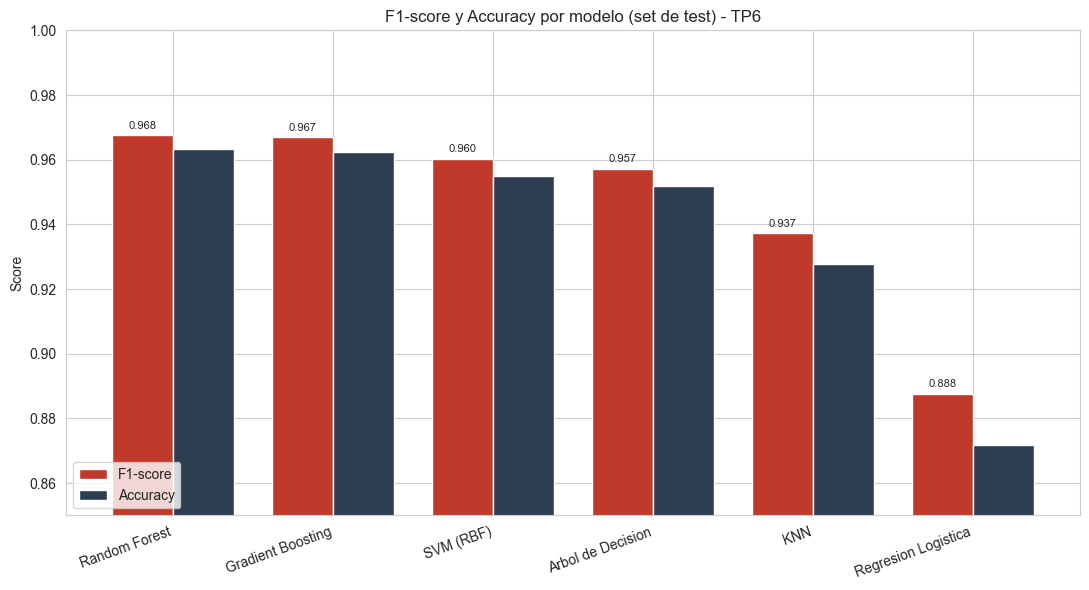

In [ ]:
# F1 y Accuracy por modelo (TP6)
orden = df_resultados.index.tolist()
x = np.arange(len(orden)); ancho = 0.38

fig, ax = plt.subplots(figsize=(11, 6))
ax.bar(x - ancho/2, df_resultados['F1-score'], ancho, label='F1-score', color='#c0392b')
ax.bar(x + ancho/2, df_resultados['Accuracy'], ancho, label='Accuracy', color='#2c3e50')
ax.set_xticks(x); ax.set_xticklabels(orden, rotation=20, ha='right')
ax.set_ylim(0.85, 1.0); ax.set_ylabel('Score'); ax.legend(loc='lower left')
ax.set_title('F1-score y Accuracy por modelo (set de test) - TP6')
for i, m in enumerate(orden):
    ax.text(i - ancho/2, df_resultados['F1-score'][m] + 0.002,
            f"{df_resultados['F1-score'][m]:.3f}", ha='center', fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / 'tp6_comparacion_metricas.png', dpi=150); plt.show()

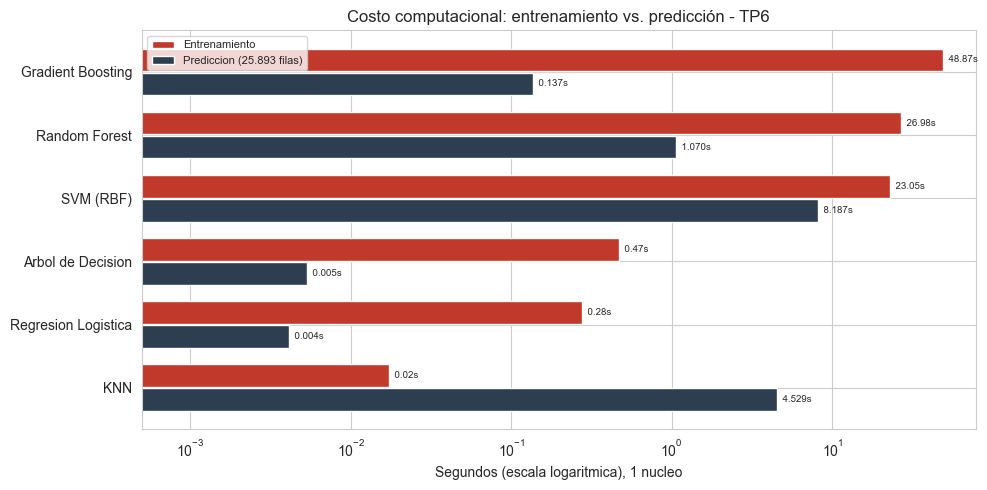

In [ ]:
# Costo computacional TP6: entrenamiento vs prediccion (escala log)
dft = df_resultados.sort_values('Tiempo_entren_seg')
yy = np.arange(len(dft))
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(yy + 0.19, dft['Tiempo_entren_seg'], 0.36, color='#c0392b', label='Entrenamiento')
ax.barh(yy - 0.19, dft['Tiempo_predic_seg'], 0.36, color='#2c3e50', label='Prediccion (25.893 filas)')
ax.set_yticks(yy); ax.set_yticklabels(dft.index)
ax.set_xscale('log'); ax.set_xlabel('Segundos (escala logaritmica), 1 nucleo')
ax.set_title('Costo computacional: entrenamiento vs. predicción - TP6')
ax.legend(loc='upper left', fontsize=8)
for i, (t1, t2) in enumerate(zip(dft['Tiempo_entren_seg'], dft['Tiempo_predic_seg'])):
    ax.text(t1, i + 0.19, f'  {t1:.2f}s', va='center', fontsize=7)
    ax.text(t2, i - 0.19, f'  {t2:.3f}s', va='center', fontsize=7)
ax.set_xlim(left=5e-4)
plt.tight_layout(); plt.savefig(FIG_DIR / 'tp6_tiempos.png', dpi=150); plt.show()

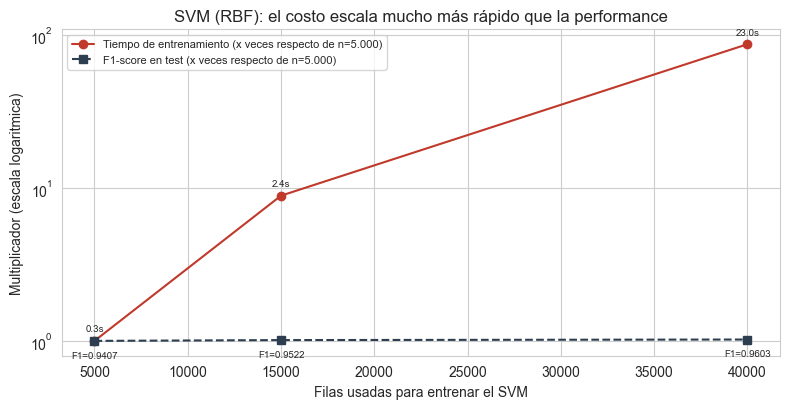

In [ ]:
# Escalabilidad del SVM: costo vs. performance, normalizados
base_t = df_curva['tiempo_seg'].iloc[0]
base_f = df_curva['f1_test'].iloc[0]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(df_curva['n'], df_curva['tiempo_seg'] / base_t, 'o-', color='#c0392b',
        label='Tiempo de entrenamiento (x veces respecto de n=5.000)')
ax.plot(df_curva['n'], df_curva['f1_test'] / base_f, 's--', color='#2c3e50',
        label='F1-score en test (x veces respecto de n=5.000)')
ax.set_yscale('log'); ax.set_xlabel('Filas usadas para entrenar el SVM')
ax.set_ylabel('Multiplicador (escala logaritmica)')
ax.set_title('SVM (RBF): el costo escala mucho más rápido que la performance')
ax.legend(fontsize=8)
for _, r in df_curva.iterrows():
    ax.annotate(f"{r['tiempo_seg']:.1f}s", (r['n'], r['tiempo_seg']/base_t),
                textcoords="offset points", xytext=(0, 7), ha='center', fontsize=7)
    ax.annotate(f"F1={r['f1_test']:.4f}", (r['n'], r['f1_test']/base_f),
                textcoords="offset points", xytext=(0, -12), ha='center', fontsize=7)
plt.tight_layout(); plt.savefig(FIG_DIR / 'tp6_svm_escalabilidad.png', dpi=150); plt.show()

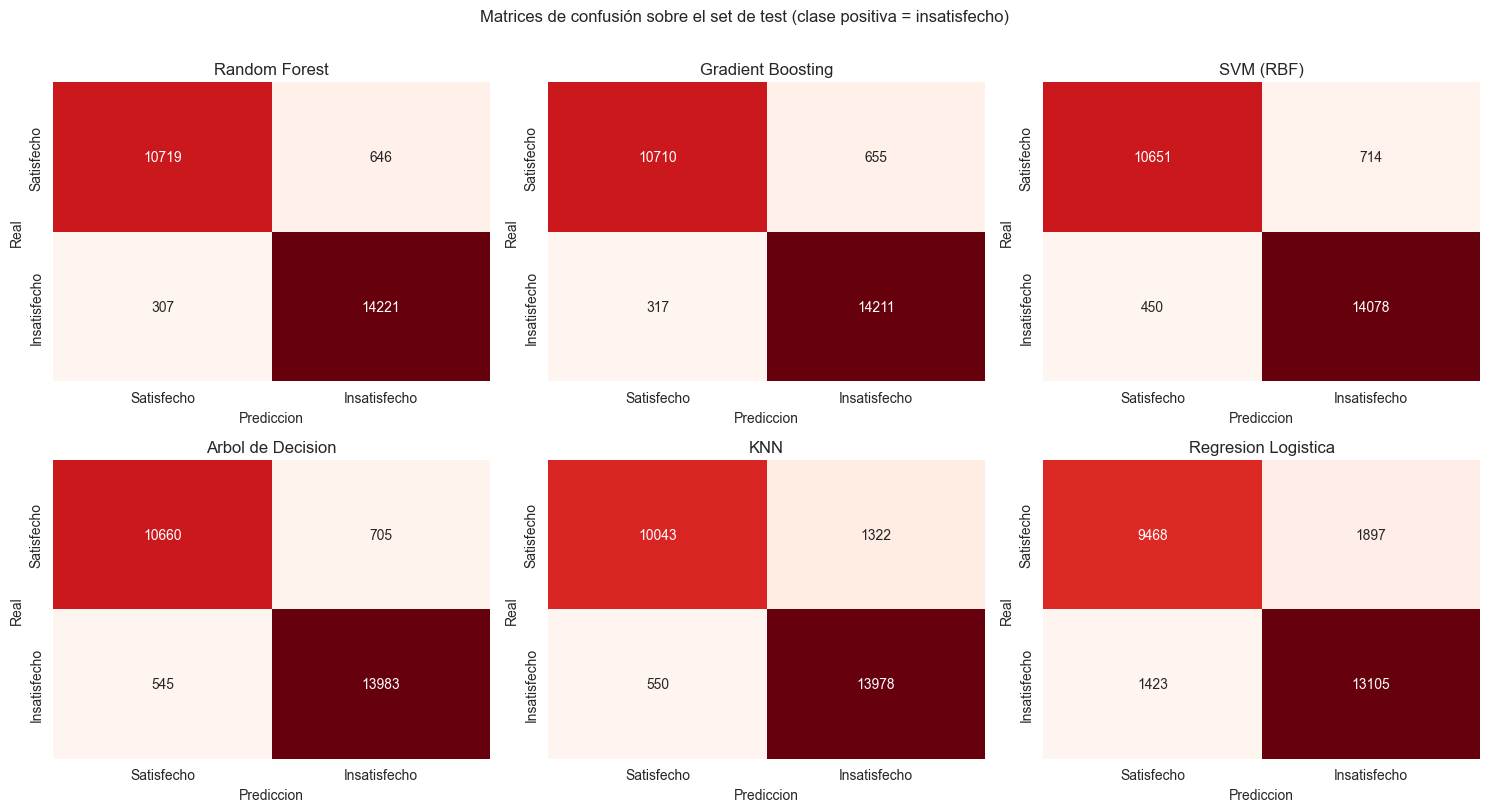

Insatisfechos no detectados (falsos negativos) por modelo:
  Random Forest          FN =   307  |  FP =   646  |  errores =   953
  Gradient Boosting      FN =   317  |  FP =   655  |  errores =   972
  SVM (RBF)              FN =   450  |  FP =   714  |  errores =  1164
  Arbol de Decision      FN =   545  |  FP =   705  |  errores =  1250
  KNN                    FN =   550  |  FP =  1322  |  errores =  1872
  Regresion Logistica    FN =  1423  |  FP =  1897  |  errores =  3320


In [ ]:
# Matrices de confusion TP6 (clase positiva = insatisfecho)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, nombre in zip(axes.ravel(), orden):
    cm = confusion_matrix(y_test, predicciones[nombre])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', cbar=False, ax=ax)
    ax.set_title(nombre); ax.set_xlabel('Prediccion'); ax.set_ylabel('Real')
    ax.set_xticklabels(['Satisfecho', 'Insatisfecho'])
    ax.set_yticklabels(['Satisfecho', 'Insatisfecho'])
plt.suptitle('Matrices de confusión sobre el set de test '
             '(clase positiva = insatisfecho)', y=1.01)
plt.tight_layout(); plt.savefig(FIG_DIR / 'tp6_matrices_confusion.png', dpi=150,
                                bbox_inches='tight'); plt.show()

# Falsos negativos = insatisfechos NO detectados (el error costoso)
print("Insatisfechos no detectados (falsos negativos) por modelo:")
for m in orden:
    cm = confusion_matrix(y_test, predicciones[m])
    print(f"  {m:22s} FN = {cm[1,0]:5d}  |  FP = {cm[0,1]:5d}  |  errores = {cm[1,0]+cm[0,1]:5d}")

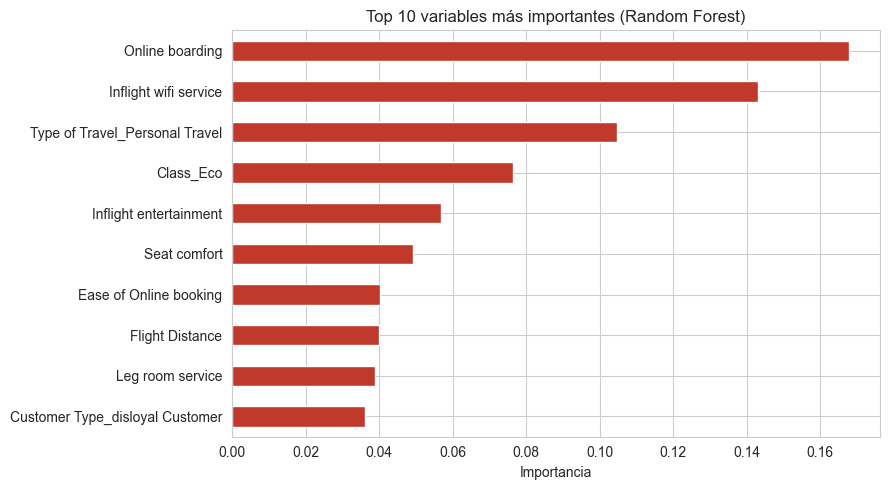

Online boarding                    0.1678
Inflight wifi service              0.1430
Type of Travel_Personal Travel     0.1046
Class_Eco                          0.0765
Inflight entertainment             0.0569
Seat comfort                       0.0493
Ease of Online booking             0.0402
Flight Distance                    0.0401
Leg room service                   0.0388
Customer Type_disloyal Customer    0.0360
dtype: float64

In [ ]:
# Importancia de variables (Random Forest)
rf = modelos_entrenados['Random Forest']
importancias = pd.Series(rf.feature_importances_, index=X_train.columns)
top10 = importancias.sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 5))
top10.sort_values().plot(kind='barh', color='#c0392b')
plt.title('Top 10 variables más importantes (Random Forest)')
plt.xlabel('Importancia'); plt.tight_layout()
plt.savefig(FIG_DIR / 'tp6_importancia_variables.png', dpi=150); plt.show()
top10.round(4)

In [ ]:
# Resumen final
print("="*78)
print("RESUMEN (ordenado por F1-score sobre la clase 'insatisfecho', set de test)")
print("="*78)
print(df_resultados.drop(columns=['Nota']).round(4).to_string())
print("\nMejor modelo por F1 en test :", df_resultados.index[0])
print("Mejor modelo por F1 en CV   :",
      max(cv_scores, key=lambda k: cv_scores[k][0]))
print("="*78)

RESUMEN (ordenado por F1-score sobre la clase 'insatisfecho', set de test)
                     Accuracy  Precision  Recall  F1-score  Tiempo_entren_seg  Tiempo_predic_seg  F1_CV_medio  F1_CV_desvio
Modelo                                                                                                                     
Random Forest          0.9632     0.9565  0.9789    0.9676            26.9763             1.0702       0.9514        0.0049
Gradient Boosting      0.9625     0.9559  0.9782    0.9669            48.8735             0.1373       0.9606        0.0033
SVM (RBF)              0.9550     0.9517  0.9690    0.9603            23.0452             8.1870       0.9431        0.0030
Arbol de Decision      0.9517     0.9520  0.9625    0.9572             0.4686             0.0053       0.9364        0.0036
KNN                    0.9277     0.9136  0.9621    0.9372             0.0174             4.5293       0.9211        0.0013
Regresion Logistica    0.8718     0.8736  0.9021    0.887

## 10. Conclusiones

*(Síntesis de las conclusiones del TP6. Los tiempos citados son los de la corrida
original del TP6; los de esta ejecución están en la tabla de la Sección 9 y pueden
variar según el equipo.)*

- **Los ensambles de arboles ganan.** Random Forest y Gradient Boosting quedan
  empatados en test (F1 0,9676 y 0,9669) y ambos superan con claridad a la
  Regresion Logistica (0,8876): la frontera de decision no es lineal.
- **El modelo recomendado es el Gradient Boosting.** Empata con el Random Forest en
  la metrica: 953 errores contra 972 sobre 25.893 filas, diecinueve de diferencia.
  Como no hay desempate metrico posible, desempata el costo: la prediccion es la
  operacion que se repite en produccion y ahi el GB es 8 veces mas rapido; entrenar
  1,6 veces mas lento le cuesta quince segundos. La validacion cruzada tambien lo
  favorece (0,9606 contra 0,9514) pero se mide sobre folds de 8.000 filas, asi que
  cuenta como evidencia secundaria. El Random Forest queda como alternativa y, al
  no estar optimizado, su 0,9676 es un piso.
- **Si el costo manda, gana la simplicidad.** El Arbol de Decision alcanza el 99%
  del F1 del Random Forest (0,9572 contra 0,9676, 1,0 punto de diferencia) a 1/60
  de su tiempo de entrenamiento y con un modelo interpretable.
- **El costo no escala con la performance.** El SVM multiplica por 97 su tiempo de
  entrenamiento entre 5.000 y 40.000 filas para ganar un 2% de F1.
- **Limite declarado.** El SVM no se entreno con el train completo (costo estimado
  ~3 min por extrapolacion, no ejecutado) y tres de los seis modelos quedaron sin
  optimizar. Ambas cosas estan dichas en el informe.
- **KNN invierte el patron.** Entrena en centesimas de segundo pero es el mas caro
  al predecir, que es la operacion que se repite en produccion.
- **Lectura de negocio.** El Gradient Boosting detecta el 97,8% de los pasajeros
  insatisfechos; las palancas con mayor peso predictivo (medidas sobre el Random
  Forest, equivalente en performance) son **Online boarding** e **Inflight wifi
  service**.

# TP 8 - Deep Learning

## 11. Recordatorio: dataset, problema y métrica (TP6)

**Contexto y problema.** Encuesta de satisfacción de pasajeros de una aerolínea
(*Airline Passenger Satisfaction*, Kaggle). Problema de **clasificación binaria**: predecir
si un pasajero queda **insatisfecho** (`1 = neutral or dissatisfied`) o **satisfecho**
(`0 = satisfied`). La clase positiva es "insatisfecho" porque el objetivo de negocio es
detectarlos para poder intervenir; el error costoso es el falso negativo.

**Variables (23 predictoras tras el feature engineering).** Demográficas (`Age`, `Gender`,
`Customer Type`), del vuelo (`Type of Travel`, `Class`, `Flight Distance`, demoras de salida
y de llegada) y 14 calificaciones de 1 a 5 sobre el servicio, donde **0 significa "no
aplica / sin respuesta"** (aparece en el 7,9% de las filas de train, sobre todo en wifi,
horario y reserva online). **Decisión:** se mantiene como valor numérico, igual que en el
TP6, para que la comparación con esos modelos sea sobre los mismos datos. Para los árboles
no es un problema (un corte en 0,5 lo aísla); para los modelos lineales y las DNN es una
codificación imperfecta, que queda declarada como limitación.

**Feature engineering (Sección 5, sin cambios).** Se eliminan `Unnamed: 0` e `id`; se
descartan las filas con nulos en `Arrival Delay in Minutes` (0,3%); se codifica el objetivo
(1/0); One-Hot Encoding con `get_dummies(drop_first=True)`; `StandardScaler` ajustado solo
con train. **Las DNN usan `X_train_scaled` / `X_test_scaled`**, porque son sensibles a la
escala.

**Métrica (Sección 6).** **F1-score sobre la clase "insatisfecho"** (que incluye a los
pasajeros *neutral*). No se usa F2, que pesa más el recall, porque los falsos positivos
también tienen costo (acciones de retención innecesarias) y porque mantener la métrica del
TP6 permite comparar los resultados. Como en el TP6, el
**recall** desempata entre modelos con F1 equivalente. Para que "equivalente" no quede a
criterio, se define la regla de decisión en la Sección 15.

In [ ]:
# Verificacion del dato citado sobre las calificaciones en 0 ("no aplica")
cols_calif = train_df.columns[8:22]
print("Columnas de calificacion:", len(cols_calif))
print("Filas de train con al menos un 0:", f"{(train_df[cols_calif] == 0).any(axis=1).mean():.1%}")
print((train_df[cols_calif] == 0).sum().sort_values(ascending=False).head(4))

Columnas de calificacion: 14
Filas de train con al menos un 0: 7.9%
Departure/Arrival time convenient    5300
Ease of Online booking               4487
Inflight wifi service                3103
Online boarding                      2428
dtype: int64


In [ ]:
# Deep Learning: TensorFlow / Keras
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # oculta logs informativos de TF
import tensorflow as tf

# Condiciones de medicion identicas a los modelos de ML (n_jobs=1): 1 hilo de CPU y sin
# GPU. Ademas se activa el determinismo de operaciones para que cada semilla sea
# reproducible. Esto tiene que ejecutarse ANTES de que TensorFlow cree cualquier tensor:
# si esta celda se re-ejecuta sin reiniciar el kernel, TF avisa y conserva la config previa.
try:
    tf.config.set_visible_devices([], 'GPU')
    tf.config.threading.set_intra_op_parallelism_threads(1)
    tf.config.threading.set_inter_op_parallelism_threads(1)
    tf.config.experimental.enable_op_determinism()
except RuntimeError as e:
    print("Aviso: TensorFlow ya estaba inicializado (reiniciar el kernel para aplicar):", e)
tf.get_logger().setLevel('ERROR')   # oculta avisos de retracing al entrenar muchas redes

# Tipografia de las figuras del informe: se insertan a ~75% de su tamano, asi que estas
# medidas quedan en ~7,5-8 pt impresas (legibles).
plt.rcParams.update({'font.size': 11, 'axes.titlesize': 12, 'axes.labelsize': 11,
                     'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 10})

from tensorflow import keras
from tensorflow.keras import layers, callbacks, regularizers
from scipy.stats import chi2

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("Hilos intra/inter-op:", tf.config.threading.get_intra_op_parallelism_threads(),
      "/", tf.config.threading.get_inter_op_parallelism_threads())
print("Equipo:", platform.platform(), "| CPU logicas:", os.cpu_count())

TensorFlow: 2.20.0 | Keras: 3.15.1
Hilos intra/inter-op: 1 / 1
Equipo: Linux-6.18.44-fc-v42-x86_64-with-glibc2.39 | CPU logicas: 2


## 12. Preparación de datos y protocolo común de entrenamiento

No hace falta un feature engineering nuevo: se reutilizan el split y el escalado del TP6.
Del train se separa un **20% estratificado de validación**, fijo para todas las redes y
todas las semillas, que usan Early Stopping y la reducción del learning rate. Por eso las
DNN aprenden con el 80% del train (82.875 filas), mientras que los modelos de ML usan el
100%. Es una desventaja para las redes y queda declarada. El **test no se toca** hasta la
evaluación final.

**Protocolo común.** Las tres redes se entrenan exactamente igual; solo cambian la
arquitectura y la regularización. Así las diferencias se pueden atribuir al modelo y no al
entrenamiento:

| Hiperparámetro | Valor | Justificación |
|---|---|---|
| Activación oculta / salida | ReLU / sigmoide | ReLU evita el desvanecimiento del gradiente; sigmoide da una probabilidad para clasificación binaria |
| Inicialización | He normal | Recomendada para capas ReLU |
| Pérdida | Entropía cruzada binaria | Estándar para salida sigmoide |
| Optimizador | Adam, lr inicial 1e-3 | Converge rápido sin ajuste fino |
| Batch size | 256 | Equilibrio entre estabilidad del gradiente y velocidad |
| Épocas máximas | 100 (iguales para las tres) | El corte real lo decide Early Stopping |
| Early Stopping | `val_loss`, paciencia 10, `restore_best_weights=True` | Evita sobreajuste y se queda con la mejor época |
| ReduceLROnPlateau | `val_loss`, factor 0,5, paciencia 4, lr mín. 1e-5 | Afina el ajuste cuando la validación se estanca |
| Umbral de decisión | 0,5 | El mismo que usan los modelos de ML (no se optimiza para no favorecer a nadie) |

In [ ]:
# Validacion fija (20% estratificado del train) para Early Stopping / ReduceLROnPlateau
X_tr_nn, X_val_nn, y_tr_nn, y_val_nn = train_test_split(
    X_train_scaled, y_train.values, test_size=0.2, stratify=y_train,
    random_state=RANDOM_STATE)
X_test_nn, y_test_nn = X_test_scaled, y_test.values
n_features = X_tr_nn.shape[1]

MAX_EPOCHS, BATCH_SIZE, LR_INICIAL = 100, 256, 1e-3
INIT = 'he_normal'

print("Features de entrada:", n_features)
print("Entrenamiento DNN:", X_tr_nn.shape, "| Validacion:", X_val_nn.shape,
      "| Test:", X_test_nn.shape)
print("Proporcion de insatisfechos -> train DNN:", round(y_tr_nn.mean(), 4),
      "| validacion:", round(y_val_nn.mean(), 4))

Features de entrada: 23
Entrenamiento DNN: (82875, 23) | Validacion: (20719, 23) | Test: (25893, 23)
Proporcion de insatisfechos -> train DNN: 0.5666 | validacion: 0.5666


### 12.1 Arquitecturas

Tres redes, de menor a mayor complejidad:

1. **DNN base** (rápida): 2 capas ocultas (16 y 8 neuronas), sin regularización. Es el
   análogo "rápido" pedido por la consigna.
2. **DNN amplia sin regularización**: la misma arquitectura que la compleja (128, 64 y 32
   neuronas) pero sin L2, Batch Normalization ni Dropout. Es un **control (ablación)**:
   permite separar cuánto aporta la **capacidad** y cuánto la **regularización**.
3. **DNN compleja regularizada**: 128, 64 y 32 neuronas con **regularización L2** (1e-4)
   en las dos capas grandes, **Batch Normalization** después de ellas y **Dropout**
   (0,3 / 0,3 / 0,2).

In [ ]:
def dnn_base():
    return keras.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(16, activation='relu', kernel_initializer=INIT),
        layers.Dense(8, activation='relu', kernel_initializer=INIT),
        layers.Dense(1, activation='sigmoid')
    ], name='DNN_base')


def dnn_sin_reg():
    return keras.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(128, activation='relu', kernel_initializer=INIT),
        layers.Dense(64, activation='relu', kernel_initializer=INIT),
        layers.Dense(32, activation='relu', kernel_initializer=INIT),
        layers.Dense(1, activation='sigmoid')
    ], name='DNN_sin_regularizacion')


def dnn_compleja():
    return keras.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(128, activation='relu', kernel_initializer=INIT,
                     kernel_regularizer=regularizers.l2(1e-4)),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(64, activation='relu', kernel_initializer=INIT,
                     kernel_regularizer=regularizers.l2(1e-4)),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(32, activation='relu', kernel_initializer=INIT),
        layers.Dropout(0.2),
        layers.Dense(1, activation='sigmoid')
    ], name='DNN_compleja')


ARQUITECTURAS = {'DNN base': dnn_base,
                 'DNN sin regularizacion': dnn_sin_reg,
                 'DNN compleja': dnn_compleja}

for nombre, constructor in ARQUITECTURAS.items():
    m = constructor()
    print(f"{nombre:24s} -> {m.count_params():6,d} parametros "
          f"({sum(int(np.prod(w.shape)) for w in m.trainable_weights):,d} entrenables)")
dnn_compleja().summary()

DNN base                 ->    529 parametros (529 entrenables)
DNN sin regularizacion   -> 13,441 parametros (13,441 entrenables)
DNN compleja             -> 14,209 parametros (13,825 entrenables)


Model: "DNN_compleja"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_11 (Dense)                │ (None, 128)            │         3,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,209 (55.50 KB)

 Trainable params: 13,825 (54.00 KB)

 Non-trainable params: 384 (1.50 KB)

### 12.2 Funciones de entrenamiento y evaluación

`entrenar_dnn()` fija la semilla, construye y compila la red, entrena con el protocolo
común y mide el tiempo de `fit`. `evaluar_dnn()` mide el tiempo de predicción sobre el test,
aplica el umbral 0,5 y reutiliza `registrar()` para sumar la red a la **misma tabla
comparativa** que los seis modelos de ML.

In [ ]:
def callbacks_comunes():
    # Instancias nuevas en cada entrenamiento (los callbacks guardan estado).
    return [callbacks.EarlyStopping(monitor='val_loss', patience=10,
                                    restore_best_weights=True),
            callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4,
                                        min_lr=1e-5)]


def entrenar_dnn(constructor, semilla, Xtr, ytr, Xval, yval, max_epocas=None):
    keras.utils.set_random_seed(semilla)          # python, numpy y TF
    modelo = constructor()
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=LR_INICIAL),
                   loss='binary_crossentropy', metrics=['accuracy'])
    t0 = time.perf_counter()
    hist = modelo.fit(Xtr, ytr, validation_data=(Xval, yval), epochs=max_epocas or MAX_EPOCHS,
                      batch_size=BATCH_SIZE, callbacks=callbacks_comunes(), verbose=0)
    t_fit = time.perf_counter() - t0
    return modelo, hist, t_fit


def predecir_dnn(modelo, X):
    t0 = time.perf_counter()
    proba = modelo.predict(X, batch_size=1024, verbose=0).ravel()
    return (proba >= 0.5).astype(int), time.perf_counter() - t0


historiales, info_dnn = {}, {}

def evaluar_dnn(nombre, constructor, semilla=RANDOM_STATE):
    modelo, hist, t_fit = entrenar_dnn(constructor, semilla, X_tr_nn, y_tr_nn,
                                       X_val_nn, y_val_nn)
    y_pred, t_pred = predecir_dnn(modelo, X_test_nn)
    epocas = len(hist.history['loss'])
    mejor = int(np.argmin(hist.history['val_loss'])) + 1
    historiales[nombre] = hist.history
    info_dnn[nombre] = {'parametros': modelo.count_params(), 'epocas_efectivas': epocas,
                        'mejor_epoca': mejor, 'corto_early_stopping': epocas < MAX_EPOCHS,
                        'lr_final': float(modelo.optimizer.learning_rate.numpy())}
    registrar(nombre, modelo, y_pred, t_fit, t_pred,
              nota=f'{epocas} epocas (mejor: {mejor}), EarlyStopping + ReduceLROnPlateau')
    print(f"Epocas: {epocas} de {MAX_EPOCHS} | mejor epoca (restaurada): {mejor} | "
          f"Early Stopping {'SI' if epocas < MAX_EPOCHS else 'NO'} corto | "
          f"lr final: {info_dnn[nombre]['lr_final']:.2e}")
    return modelo

## 13. Modelo 1 - DNN base (rápida)

In [ ]:
modelo_base = evaluar_dnn('DNN base', dnn_base)

--- DNN base ---
Accuracy 0.9568 | Precision 0.9507 | Recall 0.9736 | F1 0.9620
Tiempo entrenamiento 62.02s | Tiempo prediccion 0.16s

Epocas: 100 de 100 | mejor epoca (restaurada): 100 | Early Stopping NO corto | lr final: 5.00e-04


## 14. Modelos 2 y 3 - DNN amplia sin regularización y DNN compleja regularizada

In [ ]:
modelo_sin_reg = evaluar_dnn('DNN sin regularizacion', dnn_sin_reg)

--- DNN sin regularizacion ---
Accuracy 0.9570 | Precision 0.9561 | Recall 0.9678 | F1 0.9619
Tiempo entrenamiento 18.73s | Tiempo prediccion 0.17s

Epocas: 22 de 100 | mejor epoca (restaurada): 12 | Early Stopping SI corto | lr final: 2.50e-04


In [ ]:
modelo_compleja = evaluar_dnn('DNN compleja', dnn_compleja)

--- DNN compleja ---
Accuracy 0.9648 | Precision 0.9567 | Recall 0.9818 | F1 0.9691
Tiempo entrenamiento 101.15s | Tiempo prediccion 0.35s

Epocas: 91 de 100 | mejor epoca (restaurada): 81 | Early Stopping SI corto | lr final: 1.56e-05


In [ ]:
# Resumen de las tres redes (se usa en la tabla de hiperparametros del informe)
df_dnn_info = pd.DataFrame(info_dnn).T
df_dnn_info

,parametros,epocas_efectivas,mejor_epoca,corto_early_stopping,lr_final
DNN base,529,100,100,False,0.0005
DNN sin regularizacion,13441,22,12,True,0.00025
DNN compleja,14209,91,81,True,0.000016


### 14.1 Verificación: ¿la DNN base terminó de converger?

La DNN base agota las 100 épocas sin que la corte Early Stopping y su mejor época es la
última. Para saber cuánto le cuesta ese tope, se la reentrena con la misma semilla y el mismo
protocolo pero con **400 épocas máximas** (experimento de control: no reemplaza al modelo de
la tabla, que usa el protocolo común).

In [ ]:
m400, h400, t400 = entrenar_dnn(dnn_base, RANDOM_STATE, X_tr_nn, y_tr_nn, X_val_nn, y_val_nn,
                              max_epocas=400)
p400, _ = predecir_dnn(m400, X_test_nn)
vl = h400.history['val_loss']
base400 = {'epocas': len(vl), 'mejor_epoca': int(np.argmin(vl)) + 1,
           'F1': f1_score(y_test, p400), 'Recall': recall_score(y_test, p400),
           'FN': int(confusion_matrix(y_test, p400)[1, 0]), 'tiempo_seg': t400,
           'val_loss': {e: vl[e - 1] for e in [50, 100, 150, 200, 300, 400] if e <= len(vl)}}
print(f"DNN base con 400 epocas: {base400['epocas']} epocas, mejor {base400['mejor_epoca']}, "
      f"F1 {base400['F1']:.4f} (con 100 epocas: {f1_score(y_test, predicciones['DNN base']):.4f}), "
      f"FN {base400['FN']}, {t400:.1f}s")
print("val_loss por epoca:", {k: round(v, 5) for k, v in base400['val_loss'].items()})

DNN base con 400 epocas: 400 epocas, mejor 395, F1 0.9628 (con 100 epocas: 0.9620), FN 374, 239.4s
val_loss por epoca: {50: 0.10116, 100: 0.09497, 150: 0.09335, 200: 0.09325, 300: 0.09319, 400: 0.09316}


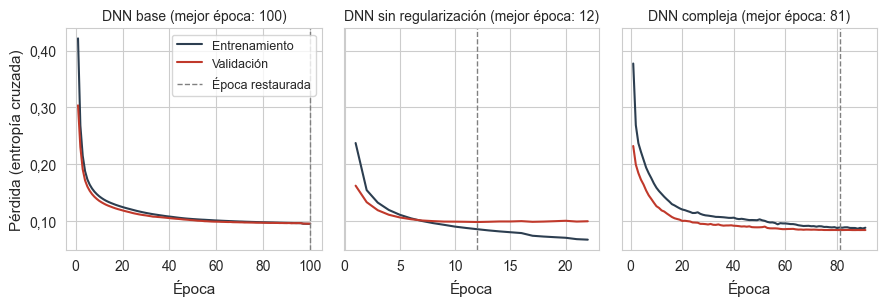

In [ ]:
# Curvas de aprendizaje (loss) de las tres redes, con la epoca restaurada marcada
TITULOS = {'DNN base': 'DNN base', 'DNN sin regularizacion': 'DNN sin regularización',
           'DNN compleja': 'DNN compleja'}
fig, axes = plt.subplots(1, 3, figsize=(9, 3.2), sharey=True)
for ax, nombre in zip(axes, ARQUITECTURAS):
    h = historiales[nombre]
    ep = np.arange(1, len(h['loss']) + 1)
    ax.plot(ep, h['loss'], color='#2c3e50', label='Entrenamiento')
    ax.plot(ep, h['val_loss'], color='#c0392b', label='Validación')
    ax.axvline(info_dnn[nombre]['mejor_epoca'], color='grey', ls='--', lw=1,
               label='Época restaurada')
    ax.set_title(f"{TITULOS[nombre]} (mejor época: {info_dnn[nombre]['mejor_epoca']})", fontsize=10)
    ax.set_xlabel('Época')
axes[0].set_ylabel('Pérdida (entropía cruzada)')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.2f}'.replace('.', ',')))
axes[0].legend(loc='upper right', fontsize=9)
plt.tight_layout(); plt.savefig(FIG_DIR / 'fig_curvas_dnn.png', dpi=250); plt.show()

**Lectura de las curvas.** La DNN sin regularización sobreajusta: después de las primeras
épocas la pérdida de entrenamiento sigue bajando mientras la de validación se estanca (mínimo
en la época 12) y Early Stopping corta en la 22. La DNN compleja entrena
91 épocas sin esa divergencia; su pérdida de validación queda por debajo de la de
entrenamiento porque Dropout y las estadísticas por batch de Batch Normalization solo actúan al
entrenar, y porque la pérdida de entrenamiento promedia una época en la que los pesos todavía
mejoran. La DNN base usa las 100 épocas y su mejor época es la 100: la Sección 14.1 muestra
que con 400 épocas su F1 apenas sube a 0,9628.

## 15. Robustez de la comparación

Una sola corrida no alcanza para afirmar que un modelo es mejor cuando las diferencias
de F1 son de milésimas: la inicialización aleatoria de una red puede mover el F1 más que
eso. Se hacen tres verificaciones:

1. **Cinco semillas** (42, 7, 123, 2024, 31415) para las tres DNN y para los dos
   ensambles con componente aleatoria (Random Forest y Gradient Boosting).
2. **Intervalo de confianza bootstrap (95%, 2.000 remuestreos pareados del test)** de la
   diferencia de F1 entre la mejor DNN y los ensambles, más el **test de McNemar** sobre
   los errores.
3. **Validación cruzada de 5 folds de las DNN** sobre la misma muestra de 10.000 filas y
   los mismos folds que los modelos de ML, para completar la columna F1 CV.

**Comparaciones.** Las dos principales son mejor DNN vs. Random Forest y mejor DNN vs.
Gradient Boosting; para ellas también se informa el IC con corrección de Bonferroni (97,5%).
Las otras tres (RF vs. GB, DNN compleja vs. base y vs. sin regularización) son descriptivas.

**Regla de decisión.** Métrica principal: F1 en test. Dos modelos se consideran
**empatados** si el IC 95% de su diferencia de F1 incluye el 0. Entre empatados desempata
el **recall** (criterio del TP6: menos insatisfechos sin detectar) y, si persiste, el
**costo de predicción y la simplicidad** del modelo.

In [ ]:
SEMILLAS = [42, 7, 123, 2024, 31415]
filas_semillas = []

def guardar(modelo_nombre, semilla, y_pred, t_fit):
    filas_semillas.append({'Modelo': modelo_nombre, 'Semilla': semilla,
                           'F1': f1_score(y_test, y_pred),
                           'Recall': recall_score(y_test, y_pred),
                           'Tiempo_entren_seg': t_fit})

# Semilla 42: modelos ya entrenados arriba (se reutilizan; mismo resultado por determinismo)
t_entren = {r['Modelo']: r['Tiempo_entren_seg'] for r in resultados}
for nombre in list(ARQUITECTURAS) + ['Random Forest', 'Gradient Boosting']:
    guardar(nombre, RANDOM_STATE, predicciones[nombre], t_entren[nombre])

t_total = time.perf_counter()
for semilla in SEMILLAS[1:]:
    for nombre, constructor in ARQUITECTURAS.items():
        m, _, t_fit = entrenar_dnn(constructor, semilla, X_tr_nn, y_tr_nn, X_val_nn, y_val_nn)
        y_pred, _ = predecir_dnn(m, X_test_nn)
        guardar(nombre, semilla, y_pred, t_fit)
    # Ensambles: n_jobs=-1 porque aca no se reporta el tiempo (no es comparable)
    rf_s = RandomForestClassifier(n_estimators=300, random_state=semilla, n_jobs=-1)
    rf_s.fit(X_train, y_train); guardar('Random Forest', semilla, rf_s.predict(X_test), np.nan)
    gb_s = GradientBoostingClassifier(random_state=semilla, **grid_gb.best_params_)
    gb_s.fit(X_train, y_train); guardar('Gradient Boosting', semilla, gb_s.predict(X_test), np.nan)
    print(f"Semilla {semilla} lista ({time.perf_counter() - t_total:.0f}s acumulados)")

df_semillas = pd.DataFrame(filas_semillas)
robustez = (df_semillas.groupby('Modelo')
            .agg(F1_media=('F1', 'mean'), F1_desvio=('F1', 'std'),
                 F1_min=('F1', 'min'), F1_max=('F1', 'max'),
                 Recall_media=('Recall', 'mean'))
            .sort_values('F1_media', ascending=False))
robustez.round(4)

Semilla 7 lista (230s acumulados)


Semilla 123 lista (477s acumulados)


Semilla 2024 lista (724s acumulados)


Semilla 31415 lista (961s acumulados)


,F1_media,F1_desvio,F1_min,F1_max,Recall_media
Modelo,,,,,
DNN compleja,0.9696,0.0005,0.9691,0.9702,0.9821
Random Forest,0.9671,0.0005,0.9665,0.9676,0.9785
Gradient Boosting,0.9669,0.0000,0.9669,0.9669,0.9782
DNN base,0.9620,0.0005,0.9613,0.9625,0.9749
DNN sin regularizacion,0.9618,0.0008,0.9609,0.9626,0.9696


In [ ]:
# Bootstrap pareado del test: IC 95% de la diferencia de F1 + test de McNemar
def f1_desde_arrays(y, p):
    tp = np.sum((y == 1) & (p == 1)); fp = np.sum((y == 0) & (p == 1))
    fn = np.sum((y == 1) & (p == 0))
    return 2 * tp / (2 * tp + fp + fn)

def comparar(modelo_a, modelo_b, n_boot=2000, semilla=RANDOM_STATE):
    y = y_test.values; pa = np.asarray(predicciones[modelo_a]); pb = np.asarray(predicciones[modelo_b])
    rng = np.random.default_rng(semilla); n = len(y); difs = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, n, n)
        difs[i] = f1_desde_arrays(y[idx], pa[idx]) - f1_desde_arrays(y[idx], pb[idx])
    ok_a, ok_b = (pa == y), (pb == y)
    b, c = int(np.sum(ok_a & ~ok_b)), int(np.sum(~ok_a & ok_b))   # discordantes
    estad = (abs(b - c) - 1) ** 2 / (b + c)                       # McNemar con correccion
    return {'A': modelo_a, 'B': modelo_b,
            'Dif_F1 (A-B)': f1_desde_arrays(y, pa) - f1_desde_arrays(y, pb),
            'IC95_inf': np.percentile(difs, 2.5), 'IC95_sup': np.percentile(difs, 97.5),
            'IC97.5_inf': np.percentile(difs, 1.25), 'IC97.5_sup': np.percentile(difs, 98.75),
            'Solo A acierta': b, 'Solo B acierta': c, 'p_McNemar': chi2.sf(estad, 1)}

mejor_dnn = robustez.loc[list(ARQUITECTURAS), 'F1_media'].idxmax()   # DNN con mejor F1 medio
print("Mejor DNN (F1 medio en 5 semillas):", mejor_dnn)
df_comparaciones = pd.DataFrame([comparar(mejor_dnn, 'Random Forest'),
                                 comparar(mejor_dnn, 'Gradient Boosting'),
                                 comparar('Random Forest', 'Gradient Boosting'),
                                 comparar('DNN compleja', 'DNN base'),
                                 comparar('DNN compleja', 'DNN sin regularizacion')])
df_comparaciones.round(4)

Mejor DNN (F1 medio en 5 semillas): DNN compleja


,A,B,Dif_F1 (A-B),IC95_inf,IC95_sup,IC97.5_inf,IC97.5_sup,Solo A acierta,Solo B acierta,p_McNemar
0,DNN compleja,Random Forest,0.0015,0.0002,0.0027,-0.0000,0.0029,206,164,0.0330
1,DNN compleja,Gradient Boosting,0.0021,0.0008,0.0034,0.0007,0.0037,224,163,0.0023
2,Random Forest,Gradient Boosting,0.0006,-0.0006,0.0019,-0.0008,0.0021,184,165,0.3353
3,DNN compleja,DNN base,0.0071,0.0056,0.0084,0.0054,0.0086,332,125,0.0000
4,DNN compleja,DNN sin regularizacion,0.0072,0.0055,0.0088,0.0054,0.0090,364,161,0.0000


In [ ]:
# Validacion cruzada de las DNN: misma muestra de 10.000 filas y mismos folds que el TP6.
# Dentro de cada fold se separa un 20% del entrenamiento para Early Stopping.
for nombre, constructor in ARQUITECTURAS.items():
    s = []
    for k, (itr, iva) in enumerate(cv.split(X_cv_sc, y_cv)):
        Xf, yf = X_cv_sc[itr], y_cv.values[itr]
        Xa, Xv, ya, yv = train_test_split(Xf, yf, test_size=0.2, stratify=yf,
                                          random_state=RANDOM_STATE)
        m, _, _ = entrenar_dnn(constructor, RANDOM_STATE + k, Xa, ya, Xv, yv)
        p, _ = predecir_dnn(m, X_cv_sc[iva])
        s.append(f1_score(y_cv.values[iva], p))
    cv_scores[nombre] = (np.mean(s), np.std(s))
    print(f"{nombre:24s} -> F1 CV = {np.mean(s):.4f} (+/- {np.std(s):.4f})")

DNN base                 -> F1 CV = 0.9357 (+/- 0.0032)


DNN sin regularizacion   -> F1 CV = 0.9365 (+/- 0.0043)


DNN compleja             -> F1 CV = 0.9484 (+/- 0.0032)


## 16. Comparación final: Machine Learning vs. Deep Learning

In [ ]:
# Tabla final: 6 modelos de ML + 3 DNN, mismo test y misma metrica principal.
df_final = pd.DataFrame(resultados).set_index('Modelo')
df_final['F1_CV_medio']  = [cv_scores[m][0] for m in df_final.index]
df_final['F1_CV_desvio'] = [cv_scores[m][1] for m in df_final.index]
df_final['F1_5semillas_media']  = [robustez['F1_media'].get(m, np.nan) for m in df_final.index]
df_final['F1_5semillas_desvio'] = [robustez['F1_desvio'].get(m, np.nan) for m in df_final.index]
cms = {m: confusion_matrix(y_test, predicciones[m]) for m in df_final.index}
df_final['FN'] = [cms[m][1, 0] for m in df_final.index]
df_final['FP'] = [cms[m][0, 1] for m in df_final.index]
df_final = df_final.sort_values('F1-score', ascending=False)
assert df_final.index.is_unique and len(df_final) == 9
df_final.to_csv('resultados_modelos_final.csv')
df_final.drop(columns=['Nota']).round(4)

,Accuracy,Precision,Recall,F1-score,Tiempo_entren_seg,Tiempo_predic_seg,F1_CV_medio,F1_CV_desvio,F1_5semillas_media,F1_5semillas_desvio,FN,FP
Modelo,,,,,,,,,,,,
DNN compleja,0.9648,0.9567,0.9818,0.9691,101.1506,0.3549,0.9484,0.0032,0.9696,0.0005,265,646
Random Forest,0.9632,0.9565,0.9789,0.9676,26.9763,1.0702,0.9514,0.0049,0.9671,0.0005,307,646
Gradient Boosting,0.9625,0.9559,0.9782,0.9669,48.8735,0.1373,0.9606,0.0033,0.9669,0.0000,317,655
DNN base,0.9568,0.9507,0.9736,0.9620,62.0248,0.1588,0.9357,0.0032,0.9620,0.0005,384,734
DNN sin regularizacion,0.9570,0.9561,0.9678,0.9619,18.7281,0.1673,0.9365,0.0043,0.9618,0.0008,468,646
SVM (RBF),0.9550,0.9517,0.9690,0.9603,23.0452,8.1870,0.9431,0.0030,NaN,NaN,450,714
Arbol de Decision,0.9517,0.9520,0.9625,0.9572,0.4686,0.0053,0.9364,0.0036,NaN,NaN,545,705
KNN,0.9277,0.9136,0.9621,0.9372,0.0174,4.5293,0.9211,0.0013,NaN,NaN,550,1322
Regresion Logistica,0.8718,0.8736,0.9021,0.8876,0.2778,0.0041,0.8901,0.0048,NaN,NaN,1423,1897


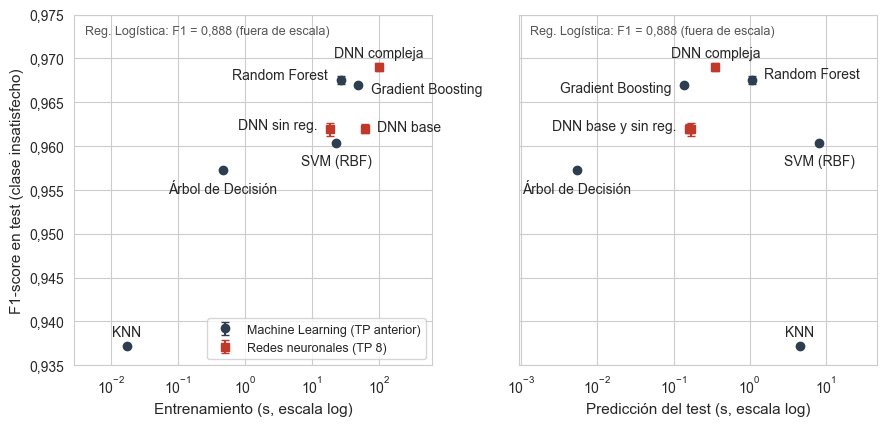

In [ ]:
# Trade-off performance vs. costo: F1 en test contra tiempo de entrenamiento y de prediccion
from matplotlib.ticker import FuncFormatter
coma3 = FuncFormatter(lambda v, _: f'{v:.3f}'.replace('.', ','))
ETQ = {'DNN compleja': 'DNN compleja', 'DNN sin regularizacion': 'DNN sin reg.',
       'DNN base': 'DNN base', 'Random Forest': 'Random Forest',
       'Gradient Boosting': 'Gradient Boosting', 'SVM (RBF)': 'SVM (RBF)',
       'Arbol de Decision': 'Árbol de Decisión', 'KNN': 'KNN',
       'Regresion Logistica': 'Reg. Logística'}
# Posicion de cada etiqueta (desplazamiento en puntos, alineacion) para que no se superpongan.
# En prediccion, DNN base y DNN sin reg. caen casi en el mismo punto: se rotulan juntas.
POS_ENTREN = {'DNN compleja': (0, 10, 'center'), 'Random Forest': (-9, 3, 'right'),
              'Gradient Boosting': (9, -3, 'left'), 'DNN base': (9, 1, 'left'),
              'DNN sin regularizacion': (-9, 3, 'right'), 'SVM (RBF)': (0, -13, 'center'),
              'Arbol de Decision': (0, -13, 'center'), 'KNN': (0, 10, 'center')}
POS_PREDIC = {'DNN compleja': (0, 10, 'center'), 'Random Forest': (9, 4, 'left'),
              'Gradient Boosting': (-9, -2, 'right'), 'DNN base': (-9, 2, 'right'),
              'DNN sin regularizacion': None, 'SVM (RBF)': (0, -13, 'center'),
              'Arbol de Decision': (0, -13, 'center'), 'KNN': (0, 10, 'center')}
ETQ_PREDIC = dict(ETQ, **{'DNN base': 'DNN base y sin reg.'})
Y_MIN = 0.935   # la Regresion Logistica (F1 ~0,89) queda fuera de escala y se indica en cada panel
fig, axes = plt.subplots(1, 2, figsize=(9, 4.4), sharey=True)
for ax, col, POS, etq, xl in zip(axes, ['Tiempo_entren_seg', 'Tiempo_predic_seg'],
                                 [POS_ENTREN, POS_PREDIC], [ETQ, ETQ_PREDIC],
                                 ['Entrenamiento (s, escala log)', 'Predicción del test (s, escala log)']):
    d_vis = df_final[df_final['F1-score'] >= Y_MIN]
    dnn = d_vis.index.str.startswith('DNN')
    for grupo, color, marcador, lab in [(~dnn, '#2c3e50', 'o', 'Machine Learning (TP anterior)'),
                                         (dnn, '#c0392b', 's', 'Redes neuronales (TP 8)')]:
        d = d_vis[grupo]
        ax.errorbar(d[col], d['F1-score'], yerr=d['F1_5semillas_desvio'].fillna(0),
                    fmt=marcador, color=color, ms=6, capsize=3, label=lab)
    for m, r in d_vis.iterrows():
        if POS[m] is None:
            continue
        dx, dy, ha = POS[m]
        ax.annotate(etq[m], (r[col], r['F1-score']), textcoords='offset points',
                    xytext=(dx, dy), ha=ha, va='center', fontsize=10)
    ax.set_xscale('log'); ax.set_xlabel(xl); ax.set_ylim(Y_MIN, 0.975)
    lx, lx2 = ax.get_xlim(); ax.set_xlim(lx / 4, lx2 * 4)
    for m, r in df_final[df_final['F1-score'] < Y_MIN].iterrows():
        ax.annotate(f"{ETQ[m]}: F1 = " + f"{r['F1-score']:.3f}".replace('.', ',') + ' (fuera de escala)',
                    xy=(0.03, 0.97), xycoords='axes fraction', va='top', fontsize=9, color='#555555')
axes[0].set_ylabel('F1-score en test (clase insatisfecho)')
axes[0].yaxis.set_major_formatter(coma3)
axes[0].legend(loc='lower right', fontsize=9)
plt.tight_layout(); plt.savefig(FIG_DIR / 'fig_tradeoff.png', dpi=250); plt.show()

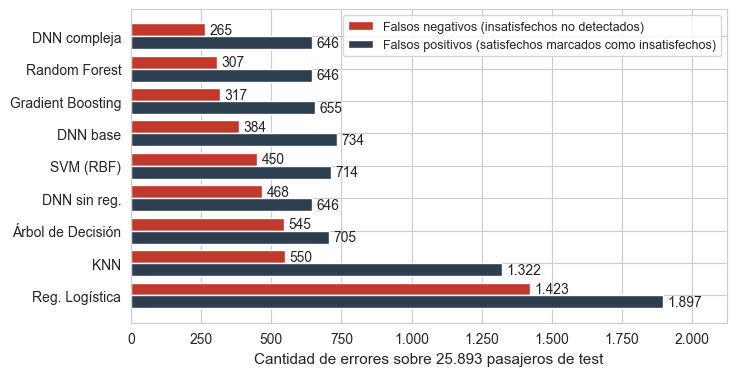

In [ ]:
# Errores por modelo: falsos negativos (insatisfechos no detectados) y falsos positivos
d = df_final.sort_values('FN', ascending=False)
yy = np.arange(len(d))
fig, ax = plt.subplots(figsize=(7.5, 3.9))
ax.barh(yy + 0.2, d['FN'], 0.4, color='#c0392b', label='Falsos negativos (insatisfechos no detectados)')
ax.barh(yy - 0.2, d['FP'], 0.4, color='#2c3e50', label='Falsos positivos (satisfechos marcados como insatisfechos)')
for i, (fn, fp) in enumerate(zip(d['FN'], d['FP'])):
    ax.text(fn + 15, i + 0.2, f'{fn:,}'.replace(',', '.'), va='center', fontsize=10)
    ax.text(fp + 15, i - 0.2, f'{fp:,}'.replace(',', '.'), va='center', fontsize=10)
ax.set_yticks(yy); ax.set_yticklabels([ETQ[m] for m in d.index])
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}'.replace(',', '.')))
ax.set_xlabel(f'Cantidad de errores sobre {len(y_test):,} pasajeros de test'.replace(',', '.'))
ax.set_xlim(0, d[['FN', 'FP']].values.max() * 1.12)
ax.legend(loc='upper right', fontsize=9)
plt.tight_layout(); plt.savefig(FIG_DIR / 'fig_errores.png', dpi=250); plt.show()

In [ ]:
print("=" * 96)
print("RESUMEN FINAL (ordenado por F1-score sobre la clase 'insatisfecho', set de test)")
print("=" * 96)
print(df_final.drop(columns=['Nota']).round(4).to_string())
print("\nRobustez (5 semillas):"); print(robustez.round(4).to_string())
print("\nComparaciones pareadas:"); print(df_comparaciones.round(4).to_string())

# Todos los numeros que cita el informe, en un archivo (el informe se arma desde aca)
import json
informe = {'robustez': robustez.round(6).to_dict(orient='index'),
           'comparaciones': df_comparaciones.to_dict(orient='records'),
           'mejor_dnn': mejor_dnn, 'info_dnn': df_dnn_info.to_dict(orient='index'),
           'base400': base400,
           'pct_ceros': float((train_df[cols_calif] == 0).any(axis=1).mean() * 100),
           'n_tr_dnn': int(len(y_tr_nn)), 'n_val_dnn': int(len(y_val_nn)),
           'equipo': f"{platform.platform()} | CPU logicas: {os.cpu_count()}", 'tf': tf.__version__}
with open('resultados_informe.json', 'w', encoding='utf-8') as fh:
    json.dump(informe, fh, ensure_ascii=False, indent=1, default=float)
print("resultados_informe.json guardado")
print("=" * 96)

RESUMEN FINAL (ordenado por F1-score sobre la clase 'insatisfecho', set de test)
                        Accuracy  Precision  Recall  F1-score  Tiempo_entren_seg  Tiempo_predic_seg  F1_CV_medio  F1_CV_desvio  F1_5semillas_media  F1_5semillas_desvio    FN    FP
Modelo                                                                                                                                                                             
DNN compleja              0.9648     0.9567  0.9818    0.9691           101.1506             0.3549       0.9484        0.0032              0.9696               0.0005   265   646
Random Forest             0.9632     0.9565  0.9789    0.9676            26.9763             1.0702       0.9514        0.0049              0.9671               0.0005   307   646
Gradient Boosting         0.9625     0.9559  0.9782    0.9669            48.8735             0.1373       0.9606        0.0033              0.9669               0.0000   317   655
DNN base           

## 17. Conclusiones de Deep Learning

- **¿Qué modelo usaríamos? La DNN compleja.** Mayor F1 en test (0,9691; 0,9696 ± 0,0005 en cinco
  semillas) y mayor recall (0,9818). Frente a Random Forest la diferencia es 0,0015 (IC 95%:
  0,0002 a 0,0027) y frente a Gradient Boosting 0,0021 (IC 95%: 0,0008 a 0,0034). Es una
  **ventaja marginal**: con corrección de Bonferroni, frente a Random Forest el IC pasa a -0,0000 a
  0,0029. Aun como empate, el recall desempata a su favor (0,9818 contra 0,9789). Deja sin
  detectar 265 insatisfechos contra 307 de Random Forest y 317 de Gradient Boosting, con 646
  falsos positivos (Random Forest: 646), y predice más rápido que Random Forest. Cambia la recomendación
  del TP6 (Gradient Boosting, elegido allí por costo de predicción).
- **¿Hacen falta redes neuronales? No son imprescindibles.** Los ensambles quedan a
  0,0015–0,0021 de F1, son más simples y más interpretables; en la validación cruzada con
  10.000 filas Gradient Boosting supera a la red (0,9606 contra 0,9484).
- **La capacidad sola no alcanza.** La red amplia sin regularización (0,9619) rinde como la base
  (0,9620; 0,9628 con 400 épocas); agregar L2 + Batch Normalization + Dropout a esa misma
  arquitectura suma 0,0072 de F1.
- **Limitaciones:** SVM con 40.000 filas; DNN sin búsqueda de hiperparámetros y entrenadas con el 80%
  del train; umbral fijo en 0,5; calificaciones en 0 tratadas como numéricas; modelo elegido sobre el
  mismo test en el que se reporta; tiempos medidos en un solo equipo (Linux-6.18.44-fc-v42-x86_64-with-glibc2.39 | CPU logicas: 2).